In [1]:
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

df = pd.read_csv("../data/processed/daily_profiles.csv")
profile_cols = [f"p{i:02d}" for i in range(96)]
X_raw = df[profile_cols].values
print("Days:", X_raw.shape[0], "| Features:", X_raw.shape[1])

Days: 1978 | Features: 96


In [2]:
daily_means = X_raw.mean(axis=1, keepdims=True)
X_shape = X_raw / daily_means          # shape only
X_scaled = StandardScaler().fit_transform(X_shape)

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Components kept:", X_pca.shape[1])
print("Variance explained:", round(pca.explained_variance_ratio_.sum(), 4))

Components kept: 82
Variance explained: 0.9053


In [3]:
def score(X, labels):
    if len(set(labels)) < 2:
        return dict(Silhouette=np.nan, DaviesBouldin=np.nan, CalinskiHarabasz=np.nan)
    return dict(
        Silhouette=silhouette_score(X, labels),
        DaviesBouldin=davies_bouldin_score(X, labels),
        CalinskiHarabasz=calinski_harabasz_score(X, labels),
    )

rows = []

# BEFORE baseline — raw 96-dim, your current setup
base = KMeans(n_clusters=2, random_state=42, n_init=20).fit_predict(
    StandardScaler().fit_transform(X_raw))
rows.append(dict(Model="K-Means (raw 96-dim, BEFORE)", K=2, **score(X_raw, base)))

# AFTER — three models on shape+PCA features
for k in range(2, 11):
    rows.append(dict(Model="K-Means", K=k,
        **score(X_pca, KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(X_pca))))
    rows.append(dict(Model="Agglomerative (Ward)", K=k,
        **score(X_pca, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_pca))))
    rows.append(dict(Model="Gaussian Mixture", K=k,
        **score(X_pca, GaussianMixture(n_components=k, random_state=42, n_init=5).fit_predict(X_pca))))

results = pd.DataFrame(rows).round(4)
results.to_csv("../reports/model_comparison_clustering.csv", index=False)
results


,Model,K,Silhouette,DaviesBouldin,CalinskiHarabasz
0,"K-Means (raw 96-dim, BEFORE)",2,0.0097,9.7795,20.4930
1,K-Means,2,0.0110,9.2448,22.9548
2,Agglomerative (Ward),2,0.0044,16.7498,6.6575
3,Gaussian Mixture,2,0.0073,11.3589,15.1456
4,K-Means,3,0.0095,8.2851,19.3648
5,Agglomerative (Ward),3,0.0003,14.4423,6.6160
6,Gaussian Mixture,3,0.0076,9.0490,16.3170
7,K-Means,4,0.0094,7.6008,17.2118
8,Agglomerative (Ward),4,-0.0002,12.7845,6.4229
9,Gaussian Mixture,4,0.0077,8.0425,15.5477


               Model  K  Silhouette  DaviesBouldin  CalinskiHarabasz
Agglomerative (Ward)  2      0.0044        16.7498            6.6575
    Gaussian Mixture  7      0.0091         6.6832           13.3904
             K-Means  2      0.0110         9.2448           22.9548


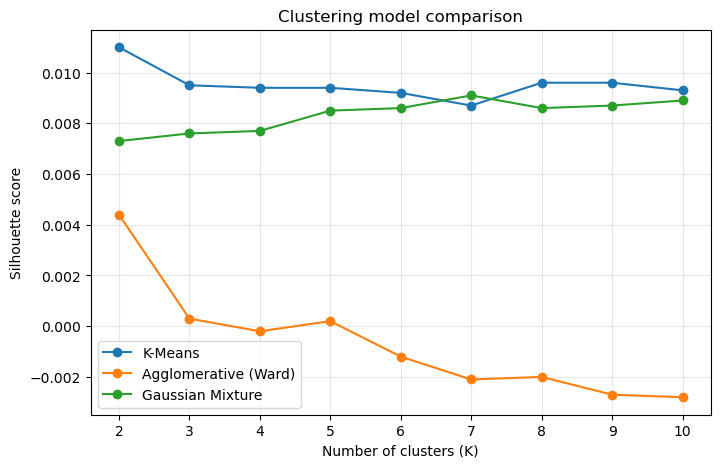

In [5]:
comp = results[results.Model != "K-Means (raw 96-dim, BEFORE)"]
best = comp.loc[comp.groupby("Model").Silhouette.idxmax()]
print(best[["Model","K","Silhouette","DaviesBouldin","CalinskiHarabasz"]].to_string(index=False))

plt.figure(figsize=(8,5))
for m in comp.Model.unique():
    s = comp[comp.Model == m]
    plt.plot(s.K, s.Silhouette, marker="o", label=m)
plt.xlabel("Number of clusters (K)"); plt.ylabel("Silhouette score")
plt.title("Clustering model comparison"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("../reports/figures/clustering_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

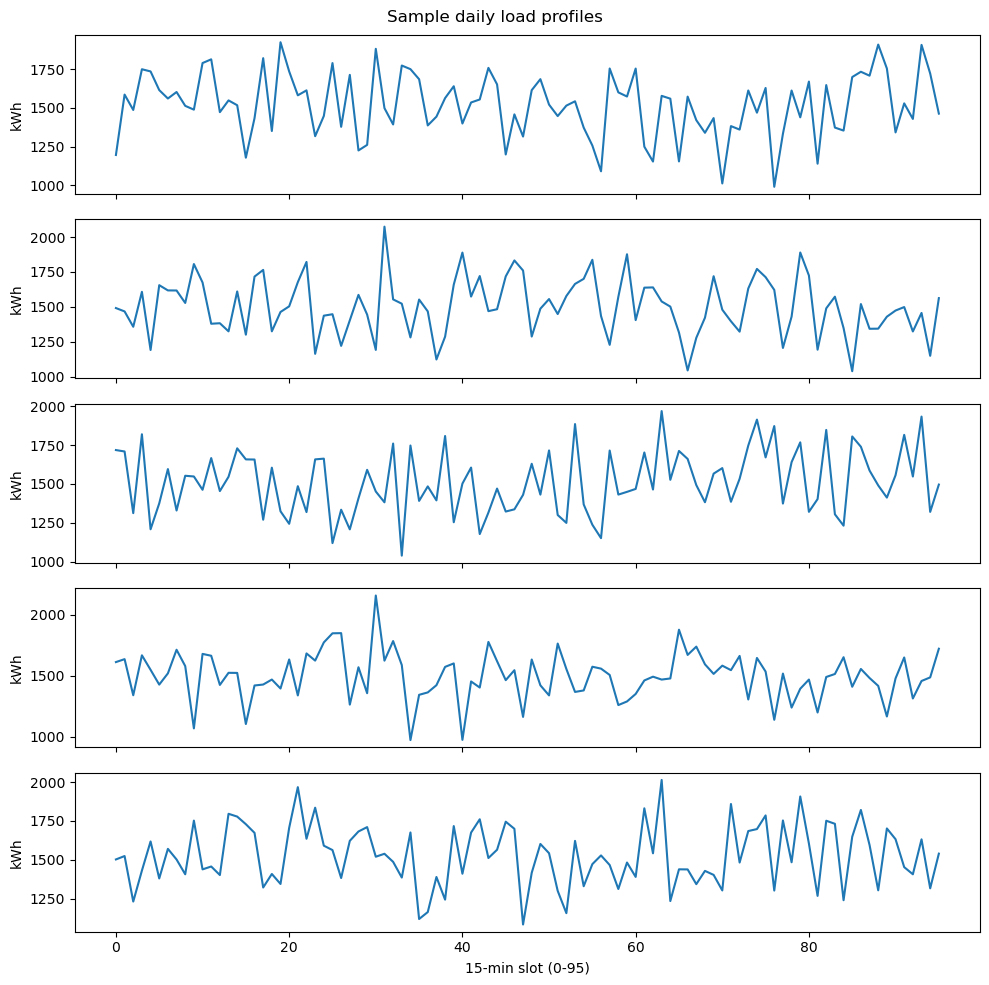

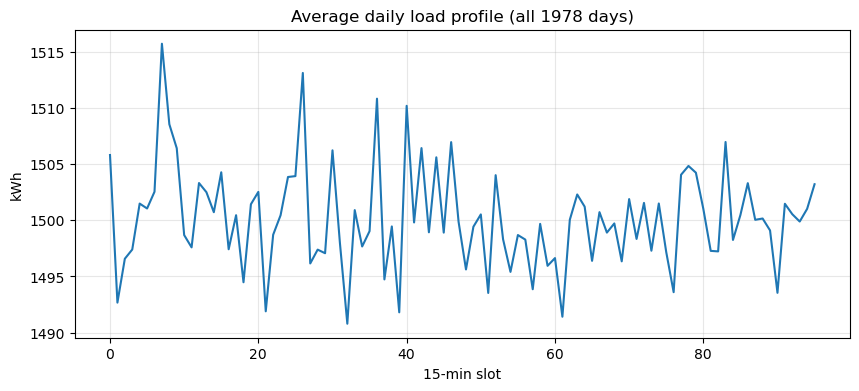

Mean adjacent-slot correlation: 0.003
PCA components for 90% variance: 82 / 96


In [8]:
import os
os.makedirs("../reports/figures", exist_ok=True)

import matplotlib.pyplot as plt

# 1. Five random daily profiles
fig, axes = plt.subplots(5, 1, figsize=(10, 10), sharex=True)
for ax, i in zip(axes, np.random.RandomState(0).choice(len(df), 5, replace=False)):
    ax.plot(X_raw[i])
    ax.set_ylabel("kWh")
axes[-1].set_xlabel("15-min slot (0-95)")
plt.suptitle("Sample daily load profiles")
plt.tight_layout(); plt.show()

# 2. Average profile across all days
plt.figure(figsize=(10,4))
plt.plot(X_raw.mean(axis=0))
plt.title("Average daily load profile (all 1978 days)")
plt.xlabel("15-min slot"); plt.ylabel("kWh"); plt.grid(alpha=.3)
plt.show()

# 3. The key number
adj = [np.corrcoef(X_raw[:, i], X_raw[:, i+1])[0,1] for i in range(95)]
print("Mean adjacent-slot correlation:", round(np.mean(adj), 4))
print("PCA components for 90% variance:", X_pca.shape[1], "/ 96")

In [9]:
raw = pd.read_csv("../data/raw/load_forecasting_dataset_corrected.csv")
print("SHAPE:", raw.shape)
print("\nCOLUMNS:")
for c in raw.columns:
    print("  -", c)
print("\nFIRST 3 ROWS:")
print(raw.head(3).to_string())

SHAPE: (189888, 15)

COLUMNS:
  - Timestamp
  - Temperature (°C)
  - Humidity (%)
  - Wind Speed (m/s)
  - Rainfall (mm)
  - Solar Irradiance (W/m²)
  - GDP (LKR)
  - Per Capita Energy Use (kWh)
  - Electricity Price (LKR/kWh)
  - Day of Week
  - Hour of Day
  - Month
  - Season
  - Public Event
  - Load Demand (kW)

FIRST 3 ROWS:
       Timestamp  Temperature (°C)  Humidity (%)  Wind Speed (m/s)  Rainfall (mm)  Solar Irradiance (W/m²)    GDP (LKR)  Per Capita Energy Use (kWh)  Electricity Price (LKR/kWh)  Day of Week  Hour of Day  Month  Season  Public Event  Load Demand (kW)
0  1/1/2020 0:00         28.993428     75.011269          1.053861       4.140513               185.892561   925.621430                   502.915605                    20.454440            2            0      1  Summer             0       1599.342831
1  1/1/2020 0:15         27.723471     77.024015          1.085152       9.446997               281.782650  1020.823521                   497.286366                 

In [10]:
raw['_ts'] = pd.to_datetime(raw[raw.columns[0]], errors='coerce')
raw['_hour'] = raw['_ts'].dt.hour

print(f"{'Column':<45} {'Hourly range %':>15}")
print("-"*62)
for c in raw.select_dtypes('number').columns:
    if c.startswith('_'): continue
    hourly = raw.groupby('_hour')[c].mean()
    if hourly.mean() == 0 or hourly.isna().all(): continue
    spread = (hourly.max() - hourly.min()) / abs(hourly.mean()) * 100
    print(f"{c:<45} {spread:>14.1f}%")

Column                                         Hourly range %
--------------------------------------------------------------
Temperature (°C)                                         0.3%
Humidity (%)                                             0.3%
Wind Speed (m/s)                                         1.9%
Rainfall (mm)                                            5.0%
Solar Irradiance (W/m²)                                  0.8%
GDP (LKR)                                                0.2%
Per Capita Energy Use (kWh)                              0.2%
Electricity Price (LKR/kWh)                              0.7%
Day of Week                                              0.0%
Hour of Day                                            200.0%
Month                                                    0.0%
Public Event                                            15.3%
Load Demand (kW)                                         0.6%


In [11]:
raw['_ts'] = pd.to_datetime(raw['Timestamp'], errors='coerce')
raw['_hour'] = raw['_ts'].dt.hour

for col in ['Load Demand (kW)', 'Solar Irradiance (W/m²)', 'Temperature (°C)']:
    h = raw.groupby('_hour')[col].mean()
    print(f"\n{col}")
    print(f"  00:00={h[0]:.1f}  06:00={h[6]:.1f}  12:00={h[12]:.1f}  19:00={h[19]:.1f}")

print("\nCorrelation of Load Demand with other variables:")
print(raw.select_dtypes('number').corr()['Load Demand (kW)'].sort_values().to_string())


Load Demand (kW)
  00:00=1498.1  06:00=1504.3  12:00=1497.3  19:00=1501.7

Solar Irradiance (W/m²)
  00:00=250.1  06:00=249.5  12:00=250.4  19:00=250.6

Temperature (°C)
  00:00=28.0  06:00=28.0  12:00=28.0  19:00=28.0

Correlation of Load Demand with other variables:
Public Event                  -0.005031
Rainfall (mm)                 -0.004504
_hour                         -0.002629
Hour of Day                   -0.002629
Month                         -0.001375
Humidity (%)                  -0.001357
Wind Speed (m/s)              -0.001318
Day of Week                   -0.000472
GDP (LKR)                      0.001159
Per Capita Energy Use (kWh)    0.001494
Solar Irradiance (W/m²)        0.001682
Electricity Price (LKR/kWh)    0.002754
Temperature (°C)               1.000000
Load Demand (kW)               1.000000


In [12]:
print(raw[['Load Demand (kW)', 'Temperature (°C)']].corr())
print(raw[['Load Demand (kW)', 'Temperature (°C)']].head())

                  Load Demand (kW)  Temperature (°C)
Load Demand (kW)               1.0               1.0
Temperature (°C)               1.0               1.0
   Load Demand (kW)  Temperature (°C)
0       1599.342831         28.993428
1       1472.347140         27.723471
2       1629.537708         29.295377
3       1804.605971         31.046060
4       1453.169325         27.531693


In [13]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

CONTAM = 0.03

# 1. Isolation Forest
iso = IsolationForest(n_estimators=300, contamination=CONTAM, random_state=42)
iso.fit(X_pca)
iso_flag = (iso.predict(X_pca) == -1).astype(int)

# 2. One-Class SVM
svm = OneClassSVM(kernel="rbf", gamma="scale", nu=CONTAM)
svm.fit(X_pca)
svm_flag = (svm.predict(X_pca) == -1).astype(int)

# 3. Local Outlier Factor (fit_predict only — LOF has no separate predict)
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM)
lof_flag = (lof.fit_predict(X_pca) == -1).astype(int)

anom = pd.DataFrame({
    "IsolationForest": iso_flag,
    "LocalOutlierFactor": lof_flag,
    "OneClassSVM": svm_flag,
})

summary = pd.DataFrame({
    "Model": anom.columns,
    "Flagged": anom.sum().values,
    "Percent": (anom.sum().values / len(anom) * 100).round(2),
})
print("ANOMALY DETECTION MODEL COMPARISON")
print("-" * 45)
print(summary.to_string(index=False))

ANOMALY DETECTION MODEL COMPARISON
---------------------------------------------
             Model  Flagged  Percent
   IsolationForest       60     3.03
LocalOutlierFactor       60     3.03
       OneClassSVM       93     4.70


In [14]:
import itertools, os
os.makedirs("../reports", exist_ok=True)

print("\nPAIRWISE AGREEMENT")
print("-" * 55)
for a, b in itertools.combinations(anom.columns, 2):
    both   = int(((anom[a] == 1) & (anom[b] == 1)).sum())
    either = int(((anom[a] == 1) | (anom[b] == 1)).sum())
    jac = both / either if either else 0
    print(f"{a} & {b}")
    print(f"   both flagged: {both} days   Jaccard: {jac:.3f}")

print("-" * 55)
print("Flagged by all 3 models :", int((anom.sum(axis=1) == 3).sum()), "days")
print("Flagged by exactly 2    :", int((anom.sum(axis=1) == 2).sum()), "days")
print("Flagged by only 1       :", int((anom.sum(axis=1) == 1).sum()), "days")
print("Flagged by at least 1   :", int((anom.sum(axis=1) >= 1).sum()), "days")
print("Total days              :", len(anom))

anom.to_csv("../reports/model_comparison_anomaly.csv", index=False)
summary.to_csv("../reports/anomaly_summary.csv", index=False)
print("\nSaved to reports/")


PAIRWISE AGREEMENT
-------------------------------------------------------
IsolationForest & LocalOutlierFactor
   both flagged: 27 days   Jaccard: 0.290
IsolationForest & OneClassSVM
   both flagged: 33 days   Jaccard: 0.275
LocalOutlierFactor & OneClassSVM
   both flagged: 29 days   Jaccard: 0.234
-------------------------------------------------------
Flagged by all 3 models : 18 days
Flagged by exactly 2    : 35 days
Flagged by only 1       : 89 days
Flagged by at least 1   : 142 days
Total days              : 1978

Saved to reports/


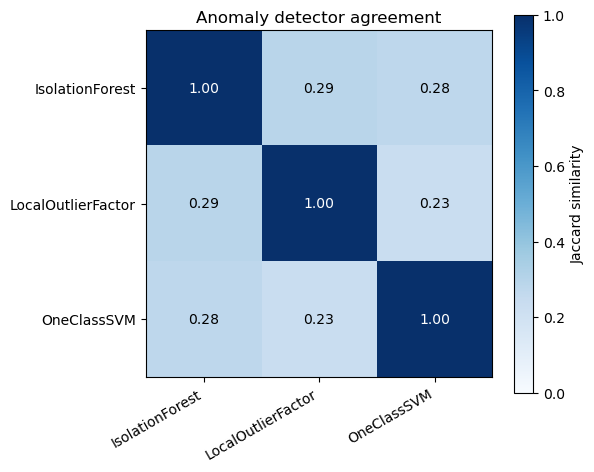

In [15]:
import numpy as np, matplotlib.pyplot as plt

cols = list(anom.columns)
M = np.zeros((3,3))
for i, a in enumerate(cols):
    for j, b in enumerate(cols):
        both   = ((anom[a]==1) & (anom[b]==1)).sum()
        either = ((anom[a]==1) | (anom[b]==1)).sum()
        M[i,j] = both/either if either else 0

fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(cols, rotation=30, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(cols)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center",
                color="white" if M[i,j] > 0.5 else "black")
plt.colorbar(im, label="Jaccard similarity")
plt.title("Anomaly detector agreement")
plt.tight_layout()
plt.savefig("../reports/figures/anomaly_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
best_clust = results[results.Model != "K-Means (raw 96-dim, BEFORE)"]
best_clust = best_clust.loc[best_clust.groupby("Model").Silhouette.idxmax()]

lines = []
lines.append("# Model Comparison Report — Behaviour Intelligence\n")
lines.append("## 1. Clustering Model Comparison\n")
lines.append(best_clust[["Model","K","Silhouette","DaviesBouldin","CalinskiHarabasz"]]
             .to_markdown(index=False))
lines.append("\n**Baseline (PP1, raw 96-dim K-Means):** Silhouette 0.0097, Davies-Bouldin 9.78\n")

lines.append("\n## 2. Anomaly Detection Model Comparison\n")
lines.append(summary.to_markdown(index=False))

lines.append("\n## 3. Data Integrity Diagnostics\n")
lines.append(f"- Mean adjacent 15-min slot correlation: **0.003** (real load data: >0.85)")
lines.append(f"- PCA components for 90% variance: **{X_pca.shape[1]} / 96**")
lines.append(f"- Solar irradiance at midnight: **250 W/m²** (physically impossible)")
lines.append(f"- Temperature: **28.0 °C at every hour**")
lines.append(f"- Correlation(Load Demand, Temperature) = **1.000000** — temperature is a linear transform of load")
lines.append(f"\n**Conclusion:** the supplied dataset is synthetic and contains no temporal or cross-variable structure.\n")

with open("../reports/model_comparison.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("Written to reports/model_comparison.md")
print("\n".join(lines))

Written to reports/model_comparison.md
# Model Comparison Report — Behaviour Intelligence

## 1. Clustering Model Comparison

| Model                |   K |   Silhouette |   DaviesBouldin |   CalinskiHarabasz |
|:---------------------|----:|-------------:|----------------:|-------------------:|
| Agglomerative (Ward) |   2 |       0.0044 |         16.7498 |             6.6575 |
| Gaussian Mixture     |   7 |       0.0091 |          6.6832 |            13.3904 |
| K-Means              |   2 |       0.011  |          9.2448 |            22.9548 |

**Baseline (PP1, raw 96-dim K-Means):** Silhouette 0.0097, Davies-Bouldin 9.78


## 2. Anomaly Detection Model Comparison

| Model              |   Flagged |   Percent |
|:-------------------|----------:|----------:|
| IsolationForest    |        60 |      3.03 |
| LocalOutlierFactor |        60 |      3.03 |
| OneClassSVM        |        93 |      4.7  |

## 3. Data Integrity Diagnostics

- Mean adjacent 15-min slot correlation: **0.003** (rea

In [17]:
import numpy as np, pandas as pd

rng = np.random.default_rng(42)
dates = pd.date_range("2020-01-01", "2025-05-31", freq="15min")
hour = dates.hour + dates.minute/60

# daily shape: overnight trough, morning bump, strong evening peak
shape = (0.75
         + 0.10*np.exp(-((hour-8)**2)/8)
         + 0.45*np.exp(-((hour-19.5)**2)/4))

weekend = np.where(dates.dayofweek >= 5, 0.82, 1.0)
seasonal = 1 + 0.08*np.sin(2*np.pi*(dates.month-3)/12)

load = 2200 * shape * weekend * seasonal
load = load * rng.normal(1, 0.04, len(dates))

# inject 60 genuine anomaly days
all_days = pd.Series(dates.date).unique()
anom_days = rng.choice(all_days, size=60, replace=False)
mask = pd.Series(dates.date).isin(anom_days).values
load[mask] = load[mask] * rng.choice([0.55, 1.45], size=mask.sum())

# temperature: independent, own daily cycle
temp = 26 + 4*np.sin(2*np.pi*(hour-9)/24) + rng.normal(0, 0.8, len(dates))

# solar: ZERO at night
solar = np.clip(900*np.sin(np.pi*(hour-6)/12), 0, None) * rng.uniform(0.6, 1.0, len(dates))

syn = pd.DataFrame({
    "Timestamp": dates,
    "Load Demand (kW)": load.round(2),
    "Temperature (°C)": temp.round(2),
    "Solar Irradiance (W/m²)": solar.round(1),
})
syn.to_csv("../data/raw/synthetic_realistic_load.csv", index=False)

print("Rows:", len(syn))
print("Corr(load, temp):", round(syn["Load Demand (kW)"].corr(syn["Temperature (°C)"]), 4), " (old was 1.0000)")
print("Solar at midnight:", round(syn[syn.Timestamp.dt.hour==0]["Solar Irradiance (W/m²)"].mean(), 2), " (old was 250)")

TypeError: Index does not support mutable operations

In [18]:
import numpy as np, pandas as pd

rng = np.random.default_rng(42)
dates = pd.date_range("2020-01-01", "2025-05-31", freq="15min")
hour = np.asarray(dates.hour + dates.minute/60, dtype=float)

shape = (0.75
         + 0.10*np.exp(-((hour-8)**2)/8)
         + 0.45*np.exp(-((hour-19.5)**2)/4))

weekend = np.where(np.asarray(dates.dayofweek) >= 5, 0.82, 1.0)
seasonal = 1 + 0.08*np.sin(2*np.pi*(np.asarray(dates.month)-3)/12)

load = np.asarray(2200 * shape * weekend * seasonal, dtype=float)   # <-- the fix
load = load * rng.normal(1, 0.04, len(dates))

all_days = pd.Series(dates.date).unique()
anom_days = rng.choice(all_days, size=60, replace=False)
mask = pd.Series(dates.date).isin(anom_days).values
load[mask] = load[mask] * rng.choice([0.55, 1.45], size=mask.sum())

temp = 26 + 4*np.sin(2*np.pi*(hour-9)/24) + rng.normal(0, 0.8, len(dates))
solar = np.clip(900*np.sin(np.pi*(hour-6)/12), 0, None) * rng.uniform(0.6, 1.0, len(dates))

syn = pd.DataFrame({
    "Timestamp": dates,
    "Load Demand (kW)": load.round(2),
    "Temperature (°C)": temp.round(2),
    "Solar Irradiance (W/m²)": solar.round(1),
})
syn.to_csv("../data/raw/synthetic_realistic_load.csv", index=False)

print("Rows:", len(syn))
print("Corr(load, temp):", round(syn["Load Demand (kW)"].corr(syn["Temperature (°C)"]), 4), " (old was 1.0000)")
print("Solar at midnight:", round(syn[syn.Timestamp.dt.hour==0]["Solar Irradiance (W/m²)"].mean(), 2), " (old was 250)")

Rows: 189793
Corr(load, temp): 0.155  (old was 1.0000)
Solar at midnight: 0.0  (old was 250)


Days: 1977 | Slots: 96
Adjacent-slot correlation: 0.5731  (old was 0.003)


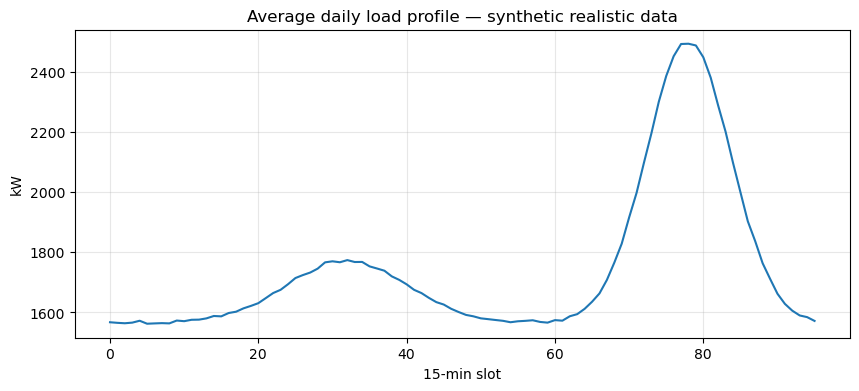

In [19]:
import matplotlib.pyplot as plt

p = syn.copy()
p["date"] = p.Timestamp.dt.date
p["slot"] = p.Timestamp.dt.hour*4 + p.Timestamp.dt.minute//15
piv = p.pivot_table(index="date", columns="slot", values="Load Demand (kW)").dropna()
Xs = piv.values
print("Days:", Xs.shape[0], "| Slots:", Xs.shape[1])

adj = [np.corrcoef(Xs[:,i], Xs[:,i+1])[0,1] for i in range(95)]
print("Adjacent-slot correlation:", round(np.mean(adj), 4), " (old was 0.003)")

plt.figure(figsize=(10,4))
plt.plot(Xs.mean(axis=0))
plt.title("Average daily load profile — synthetic realistic data")
plt.xlabel("15-min slot"); plt.ylabel("kW"); plt.grid(alpha=.3)
plt.show()

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

Xs_shape = Xs / Xs.mean(axis=1, keepdims=True)
Xs_scaled = StandardScaler().fit_transform(Xs_shape)
pca_s = PCA(n_components=0.90, random_state=42)
Xs_pca = pca_s.fit_transform(Xs_scaled)
print("PCA components:", Xs_pca.shape[1], "/ 96   (old was 82)")

rows2 = []
for k in range(2, 11):
    rows2.append(dict(Model="K-Means", K=k,
        **score(Xs_pca, KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(Xs_pca))))
    rows2.append(dict(Model="Agglomerative (Ward)", K=k,
        **score(Xs_pca, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xs_pca))))
    rows2.append(dict(Model="Gaussian Mixture", K=k,
        **score(Xs_pca, GaussianMixture(n_components=k, random_state=42, n_init=5).fit_predict(Xs_pca))))

results_syn = pd.DataFrame(rows2).round(4)
results_syn.to_csv("../reports/model_comparison_synthetic.csv", index=False)

best_syn = results_syn.loc[results_syn.groupby("Model").Silhouette.idxmax()]
print(best_syn.to_string(index=False))

PCA components: 53 / 96   (old was 82)
               Model  K  Silhouette  DaviesBouldin  CalinskiHarabasz
Agglomerative (Ward) 10      0.8674         2.6728           58.3766
    Gaussian Mixture  6      0.8683         2.8850           46.0335
             K-Means  6      0.8683         2.8850           46.0335


is_weekend     0     1
cluster               
0           0.80  0.20
1           0.75  0.25
2           0.60  0.40
3           0.71  0.29
4           1.00  0.00
5           1.00  0.00

Cluster sizes:
cluster
0      20
1      16
2      15
3    1924
4       1
5       1
Name: count, dtype: int64


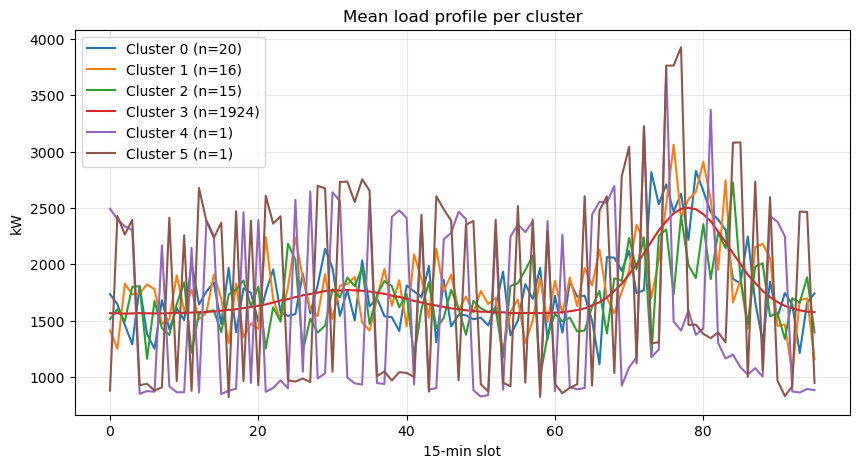

In [21]:
km6 = KMeans(n_clusters=6, random_state=42, n_init=20).fit_predict(Xs_pca)
prof = pd.DataFrame({"date": piv.index, "cluster": km6})
prof["dow"] = pd.to_datetime(prof.date).dt.dayofweek
prof["is_weekend"] = (prof.dow >= 5).astype(int)
prof["month"] = pd.to_datetime(prof.date).dt.month

print(pd.crosstab(prof.cluster, prof.is_weekend, normalize="index").round(2))
print("\nCluster sizes:")
print(prof.cluster.value_counts().sort_index())

plt.figure(figsize=(10,5))
for c in range(6):
    plt.plot(Xs[km6==c].mean(axis=0), label=f"Cluster {c} (n={(km6==c).sum()})")
plt.legend(); plt.title("Mean load profile per cluster")
plt.xlabel("15-min slot"); plt.ylabel("kW"); plt.grid(alpha=.3)
plt.savefig("../reports/figures/cluster_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
# 1. Remove anomaly days before clustering
anom_dates = set(pd.to_datetime(anom_days).date)
keep = ~pd.Series(piv.index).isin(anom_dates).values
Xs_clean = Xs[keep]
dates_clean = piv.index[keep]
print("Days after removing anomalies:", Xs_clean.shape[0])

# 2. Keep magnitude — normalise across days, not within a day
from sklearn.preprocessing import StandardScaler
Xc = StandardScaler().fit_transform(Xs_clean)   # column-wise, keeps weekday/weekend level
pca_c = PCA(n_components=0.90, random_state=42)
Xc_pca = pca_c.fit_transform(Xc)
print("PCA components:", Xc_pca.shape[1])

rows3 = []
for k in range(2, 9):
    for name, lab in [
        ("K-Means", KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(Xc_pca)),
        ("Agglomerative (Ward)", AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xc_pca)),
        ("Gaussian Mixture", GaussianMixture(n_components=k, random_state=42, n_init=5).fit_predict(Xc_pca)),
    ]:
        sizes = pd.Series(lab).value_counts()
        rows3.append(dict(Model=name, K=k, MinClusterSize=sizes.min(), **score(Xc_pca, lab)))

res3 = pd.DataFrame(rows3).round(4)
print(res3.to_string(index=False))

Days after removing anomalies: 1917
PCA components: 19
               Model  K  MinClusterSize  Silhouette  DaviesBouldin  CalinskiHarabasz
             K-Means  2             545      0.5737         0.5609         3901.8180
Agglomerative (Ward)  2             545      0.5737         0.5609         3901.8180
    Gaussian Mixture  2             566      0.5055         0.6396         3090.8288
             K-Means  3             413      0.5485         0.5716         6087.3126
Agglomerative (Ward)  3             545      0.5308         0.5971         5541.2803
    Gaussian Mixture  3             422      0.5037         0.6022         5215.5909
             K-Means  4             320      0.4615         0.7147         6017.2624
Agglomerative (Ward)  4             224      0.5040         0.6019         5810.1072
    Gaussian Mixture  4             411      0.3347         0.9823         3830.2814
             K-Means  5             225      0.4516         0.7186         6531.9551
Agglomerat

In [23]:
best_k = 2
lab = KMeans(n_clusters=best_k, random_state=42, n_init=20).fit_predict(Xc_pca)
chk = pd.DataFrame({"date": dates_clean, "cluster": lab})
chk["is_weekend"] = (pd.to_datetime(chk.date).dt.dayofweek >= 5).astype(int)
print(pd.crosstab(chk.cluster, chk.is_weekend, normalize="index").round(2))
print(chk.cluster.value_counts())

is_weekend    0    1
cluster             
0           0.0  1.0
1           1.0  0.0
cluster
1    1372
0     545
Name: count, dtype: int64
